In [686]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [687]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [688]:
from qiskit_ibm_provider import IBMProvider

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
provider = IBMProvider(token=IBM_TOKEN, instance="ibm-q-ornl/ornl/phy147")

And we get backend information.

In [574]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

Then we load our robust gateset.

In [502]:
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
)
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}

And we define a Guassian gateset to which we are going to compare.

In [50]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [51]:
qubit0, qubit1 = 47, 46 # these two have pretty good T1/T2 times
drive_amps = np.linspace(-1.2, 1.2, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [52]:
def get_robust_schedules(gate_key: str, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"{gate_key}_rabi_sched", backend=backend) as sched:
            signal = pico_gates[gate_key]
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, gate_key, amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [53]:
robust_x1_schedules = get_robust_schedules("x1", qubit0, drive_amps)
robust_x2_schedules = get_robust_schedules("x2", qubit1, drive_amps)
robust_sx1_schedules = get_robust_schedules("sx1", qubit0, drive_amps)
robust_sx2_schedules = get_robust_schedules("sx2", qubit1, drive_amps)

We do the same for the Gaussian pulses.

In [54]:
def get_gaussian_schedules(gate_key: str, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"{gate_key}_rabi_sched", backend=backend) as sched:
            signal = default_gates[gate_key].samples
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, gate_key, amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [55]:
gaussian_x1_schedules = get_gaussian_schedules("x1", qubit0, drive_amps)
gaussian_x2_schedules = get_gaussian_schedules("x2", qubit1, drive_amps)
gaussian_sx1_schedules = get_gaussian_schedules("sx1", qubit0, drive_amps)
gaussian_sx2_schedules = get_gaussian_schedules("sx2", qubit1, drive_amps)

We can use the schedules to create circuits that we can run to IBM.

In [57]:
num_qubits = backend.num_qubits
num_qubits

127

In [58]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for schedule in schedules:
        gate = qk.circuit.Gate("rabi", 1, [])
        qc = qk.QuantumCircuit(num_qubits, 1)
        qc.append(gate, [qubit])
        qc.measure(qubit, 0)
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [59]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x2_circuits = get_circuits_from_scheds(robust_x2_schedules, num_qubits, qubit1)
robust_sx1_circuits = get_circuits_from_scheds(robust_sx1_schedules, num_qubits, qubit0)
robust_sx2_circuits = get_circuits_from_scheds(robust_sx2_schedules, num_qubits, qubit1)

gaussian_x1_circuits = get_circuits_from_scheds(gaussian_x1_schedules, num_qubits, qubit0)
gaussian_x2_circuits = get_circuits_from_scheds(gaussian_x2_schedules, num_qubits, qubit1)
gaussian_sx1_circuits = get_circuits_from_scheds(gaussian_sx1_schedules, num_qubits, qubit0)
gaussian_sx2_circuits = get_circuits_from_scheds(gaussian_sx2_schedules, num_qubits, qubit1)

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [60]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: cr1jkdd8gdp0008g1jjg


In [61]:
num_shots_per_point = 1024
sampler = Sampler(backend=backend, session=session)

robust_x1_jobs = sampler.run(robust_x1_circuits, shots=num_shots_per_point)
robust_x2_jobs = sampler.run(robust_x2_circuits, shots=num_shots_per_point)
robust_sx1_jobs = sampler.run(robust_sx1_circuits, shots=num_shots_per_point)
robust_sx2_jobs = sampler.run(robust_sx2_circuits, shots=num_shots_per_point)

gaussian_x1_jobs = sampler.run(gaussian_x1_circuits, shots=num_shots_per_point)
gaussian_x2_jobs = sampler.run(gaussian_x2_circuits, shots=num_shots_per_point)
gaussian_sx1_jobs = sampler.run(gaussian_sx1_circuits, shots=num_shots_per_point)
gaussian_sx2_jobs = sampler.run(gaussian_sx2_circuits, shots=num_shots_per_point)

In [107]:
gaussian_sx2_jobs.status() 

'DONE'

We define the functions that will help us analyze the calibration data.

In [108]:
def get_rabi_values(job, shots):
    rabi_values = []
    result = job.result()
    for i in range(len(result)):
        counts = result[i].data.c.get_counts()
        rabi_values.append(counts.get("1", 0) / shots)
    return rabi_values

In [111]:
robust_x1_rabi_values = get_rabi_values(robust_x1_jobs, num_shots_per_point)
robust_x2_rabi_values = get_rabi_values(robust_x2_jobs, num_shots_per_point)
robust_sx1_rabi_values = get_rabi_values(robust_sx1_jobs, num_shots_per_point)
robust_sx2_rabi_values = get_rabi_values(robust_sx2_jobs, num_shots_per_point)

gaussian_x1_rabi_values = get_rabi_values(gaussian_x1_jobs, num_shots_per_point)
gaussian_x2_rabi_values = get_rabi_values(gaussian_x2_jobs, num_shots_per_point)
gaussian_sx1_rabi_values = get_rabi_values(gaussian_sx1_jobs, num_shots_per_point)
gaussian_sx2_rabi_values = get_rabi_values(gaussian_sx2_jobs, num_shots_per_point)

In [112]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [169]:
def get_drive_period(rabi_values: list[float], drive_amps: list[float], factor: int, plot: bool = False, normal_params: bool = True):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(baseline_remove(rabi_values))
    starting_params = [1, 1, 1.3, 0.5] if normal_params else [1, 1, 1, 0.5]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, A, B, drive_period, phi: (
            A * np.cos(2 * np.pi * x / drive_period - phi) + B
        ),
        starting_params,
    )

    drive_period = fit_params[2]  # get period of rabi oscillation
    
    if plot:
        plt.scatter(drive_amps, rabi_values, marker="x", color="black")
        plt.plot(drive_amps, y_fit)

        # plt.axvline(drive_amps[0] + drive_period / 2, linestyle="--")
        # plt.axvline(drive_amps[0], linestyle="--")
        # plt.annotate(
        #     "",
        #     xy=(drive_amps[0], 0),
        #     xytext=(drive_amps[0] + drive_period / 2, 0),
        #     arrowprops=dict(arrowstyle="<->"),
        # )
        # plt.annotate("$\pi$", xy=(drive_amps[0] - 0.03, 0.1))

        plt.xlabel("Drive amp")
        plt.ylabel("Prob. of meas. 1 (baseline removed)")
        plt.show()

    return drive_period / factor

And we get the estimated amplitudes.

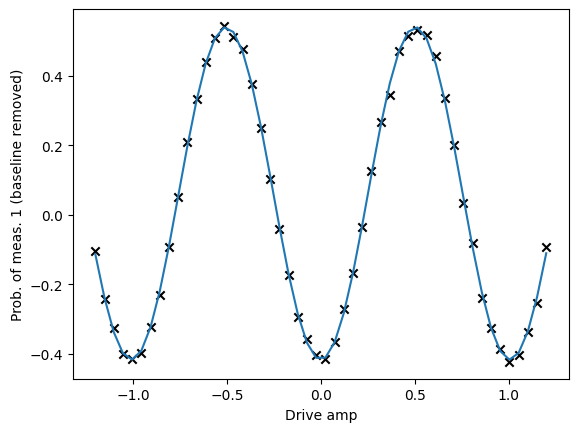

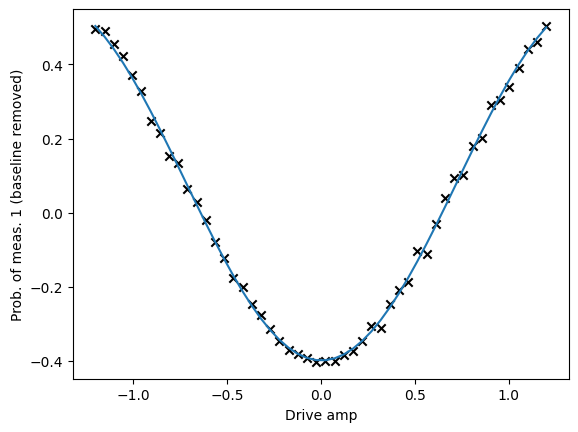

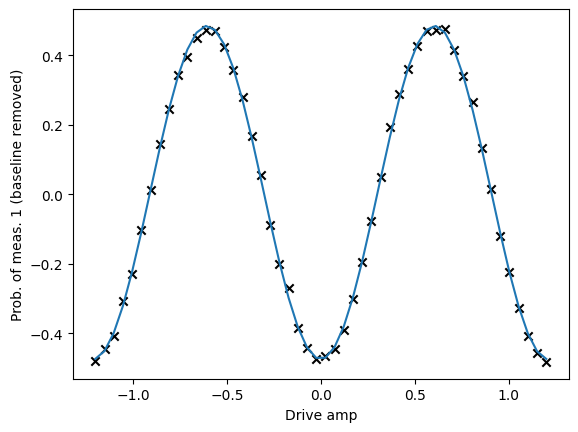

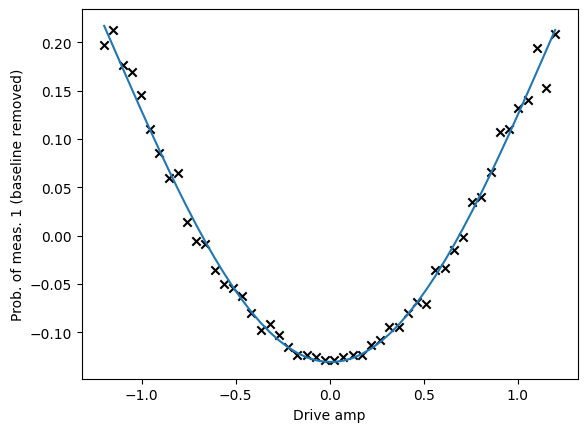

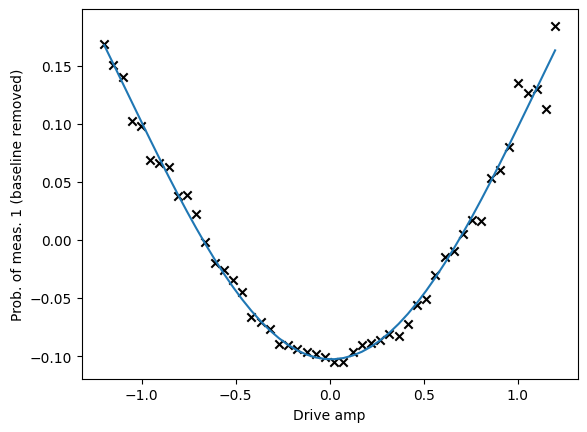

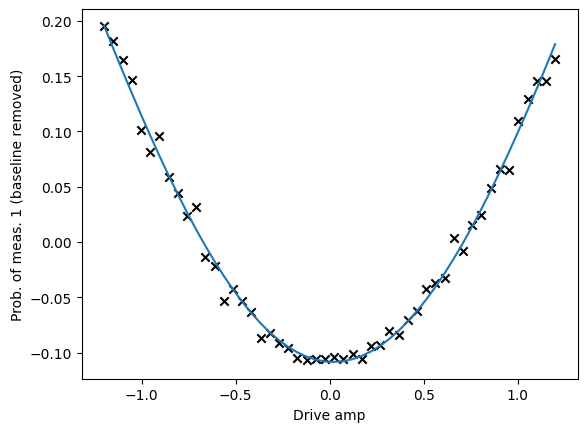

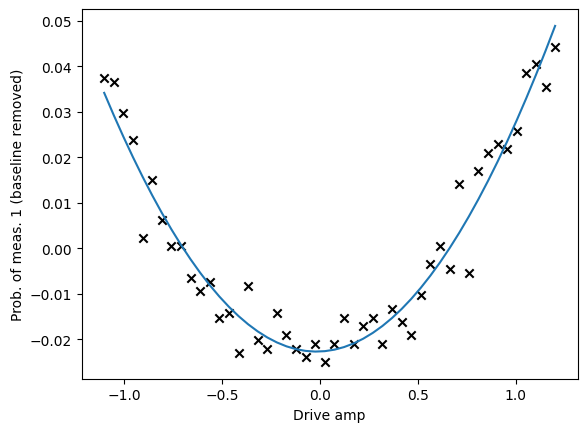

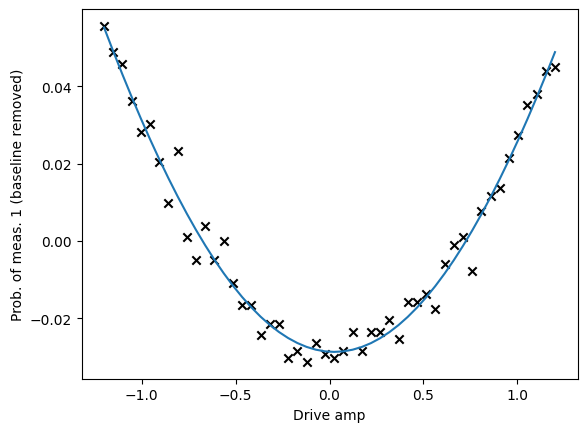

In [177]:
robust_x1_rough_amp = get_drive_period(robust_x1_rabi_values, drive_amps, 2, plot=True)
robust_x2_rough_amp = get_drive_period(robust_x2_rabi_values, drive_amps, 2, plot=True)
robust_sx1_rough_amp = get_drive_period(robust_sx1_rabi_values, drive_amps, 4, plot=True)
robust_sx2_rough_amp = get_drive_period(robust_sx2_rabi_values, drive_amps, 4, plot=True)

gaussian_x1_rough_amp = get_drive_period(gaussian_x1_rabi_values, drive_amps, 2, plot=True)
gaussian_x2_rough_amp = get_drive_period(gaussian_x2_rabi_values, drive_amps, 2, plot=True)
gaussian_sx1_rough_amp = get_drive_period(gaussian_sx1_rabi_values[2:], drive_amps[2:], 4, plot=True)
gaussian_sx2_rough_amp = get_drive_period(gaussian_sx2_rabi_values, drive_amps, 4, plot=True)

In [178]:
robust_x1_rough_amp, robust_x2_rough_amp, robust_sx1_rough_amp, robust_sx2_rough_amp, gaussian_x1_rough_amp, gaussian_x2_rough_amp, gaussian_sx1_rough_amp, gaussian_sx2_rough_amp

(0.5038183527165812,
 1.452834188254648,
 0.30279829469389163,
 1.1649514259970277,
 2.1888623071388924,
 2.9079306915928504,
 3.2769509668777475,
 2.1936120888794437)

## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [179]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [190]:
rough_robust_x1 = build_schedule(pico_gates["x1"], qubit0, robust_x1_rough_amp)
rough_robust_x2 = build_schedule(pico_gates["x2"], qubit1, robust_x2_rough_amp)
rough_robust_sx1 = build_schedule(pico_gates["sx1"], qubit0, robust_sx1_rough_amp)
rough_robust_sx2 = build_schedule(pico_gates["sx2"], qubit1, robust_sx2_rough_amp)

rough_gaussian_x1 = build_schedule(default_gates["x1"].samples, qubit0, gaussian_x1_rough_amp)
rough_gaussian_x2 = build_schedule(default_gates["x2"].samples, qubit1, gaussian_x2_rough_amp)
rough_gaussian_sx1 = build_schedule(default_gates["sx1"].samples, qubit0, gaussian_sx1_rough_amp)
rough_gaussian_sx2 = build_schedule(default_gates["sx2"].samples, qubit1, gaussian_sx2_rough_amp)

In [191]:
def get_fine_experiment(sched, qubit: int, gate: str, backend):
    d, inst_map = qk.pulse.DriveChannel(qubit), qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    exp = qk_e.library.FineXAmplitude((qubit,), backend)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

In [192]:
fine_robust_x1_exp = get_fine_experiment(rough_robust_x1, qubit0, "x", backend)
fine_robust_x2_exp = get_fine_experiment(rough_robust_x2, qubit1, "x", backend)
fine_robust_sx1_exp = get_fine_experiment(rough_robust_sx1, qubit0, "sx", backend)
fine_robust_sx2_exp = get_fine_experiment(rough_robust_sx2, qubit1, "sx", backend)

fine_gaussian_x1_exp = get_fine_experiment(rough_gaussian_x1, qubit0, "x", backend)
fine_gaussian_x2_exp = get_fine_experiment(rough_gaussian_x2, qubit1, "x", backend)
fine_gaussian_sx1_exp = get_fine_experiment(rough_gaussian_sx1, qubit0, "sx", backend)
fine_gaussian_sx2_exp = get_fine_experiment(rough_gaussian_sx2, qubit1, "sx", backend)

In [ ]:
fine_robust_x1_job = fine_robust_x1_exp.run(backend=backend)
fine_robust_x2_job = fine_robust_x2_exp.run(backend=backend)
fine_robust_sx1_job = fine_robust_sx1_exp.run(backend=backend)
fine_robust_sx2_job = fine_robust_sx2_exp.run(backend=backend)

fine_gaussian_x1_job = fine_gaussian_x1_exp.run(backend=backend)
fine_gaussian_x2_job = fine_gaussian_x2_exp.run(backend=backend)
fine_gaussian_sx1_job = fine_gaussian_sx1_exp.run(backend=backend)
fine_gaussian_sx2_job = fine_gaussian_sx2_exp.run(backend=backend)

In [291]:
fine_gaussian_sx2_job.status()

<ExperimentStatus.DONE: 'experiment jobs and analysis have successfully run'>

In [312]:
def get_fine_amplitude_estimation(job, target_angle: float):
    exp_data = job.block_for_results()
    dtheta = exp_data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [313]:
fine_robust_x1_amp = get_fine_amplitude_estimation(fine_robust_x1_job, np.pi) * robust_x1_rough_amp
fine_robust_x2_amp = get_fine_amplitude_estimation(fine_robust_x2_job, np.pi) * robust_x2_rough_amp
fine_robust_sx1_amp = get_fine_amplitude_estimation(fine_robust_sx1_job, np.pi / 2) * robust_sx1_rough_amp
fine_robust_sx2_amp = get_fine_amplitude_estimation(fine_robust_sx2_job, np.pi / 2) * robust_sx2_rough_amp

fine_gaussian_x1_amp = get_fine_amplitude_estimation(fine_gaussian_x1_job, np.pi) * gaussian_x1_rough_amp
fine_gaussian_x2_amp = get_fine_amplitude_estimation(fine_gaussian_x2_job, np.pi) * gaussian_x2_rough_amp
fine_gaussian_sx1_amp = get_fine_amplitude_estimation(fine_gaussian_sx1_job, np.pi / 2) * gaussian_sx1_rough_amp
fine_gaussian_sx2_amp = get_fine_amplitude_estimation(fine_gaussian_sx2_job, np.pi / 2) * gaussian_sx2_rough_amp

## Randomized benchmarking

Using our final estimated amplitude, we can run a randomized benchmarking protocol to measure the fidelity of our robust gateset compared to the Gaussian gateset. We will first run four one-qubit RB experiments:
- Robust gates on qubit 0
- Robust gates on qubit 1
- Gaussian gates on qubit 0
- Gaussian gates on qubit 1

Then, we run two two-qubit RB experiments:
- Robust gates on qubits 0 and 1
- Gaussian gates on qubits 0 and 1

First, we define our calibrated schedules.

In [533]:
fine_robust_x1 = build_schedule(pico_gates["x1"], qubit0, fine_robust_x1_amp)
fine_robust_x2 = build_schedule(pico_gates["x2"], qubit1, fine_robust_x2_amp)
fine_robust_sx1 = build_schedule(pico_gates["sx1"], qubit0, fine_robust_sx1_amp)
fine_robust_sx2 = build_schedule(pico_gates["sx2"], qubit1, fine_robust_sx2_amp)

fine_gaussian_x1 = build_schedule(default_gates["x1"].samples, qubit0, fine_gaussian_x1_amp)
fine_gaussian_x2 = build_schedule(default_gates["x2"].samples, qubit1, fine_gaussian_x2_amp)
fine_gaussian_sx1 = build_schedule(default_gates["sx1"].samples, qubit0, fine_gaussian_sx1_amp)
fine_gaussian_sx2 = build_schedule(default_gates["sx2"].samples, qubit1, fine_gaussian_sx2_amp)

And we create new copies of the backend object since we are going to mess with the instruction schedule map.

In [534]:
robust_backend = service.get_backend("ibm_nazca")
gaussian_backend = service.get_backend("ibm_nazca")

In [535]:
def set_backend_calibrations(backend, qubit0: int, qubit1: int, schedules):
    """
    Schedules are expected to be in the order:
    - (x, qubit0)
    - (x, qubit1)
    - (sx, qubit0)
    - (sx, qubit1)

    https://github.com/Qiskit-Extensions/qiskit-experiments/issues/1032
    """
    for i, qubit in enumerate([qubit0, qubit1]):
        backend.target["x"][(qubit,)].calibration = schedules[i]
        backend.target.update_instruction_properties("x", (qubit,), qk.transpiler.InstructionProperties(calibration=schedules[i]))

        backend.target["sx"][(qubit,)].calibration = schedules[i + 2]
        backend.target.update_instruction_properties("sx", (qubit,), qk.transpiler.InstructionProperties(calibration=schedules[i + 2]))
    return backend

In [ ]:
robust_backend = set_backend_calibrations(robust_backend, qubit0, qubit1, [fine_robust_x1, fine_robust_x2, fine_robust_sx1, fine_robust_sx2])
gaussian_backend = set_backend_calibrations(gaussian_backend, qubit0, qubit1, [fine_gaussian_x1, fine_gaussian_x2, fine_gaussian_sx1, fine_gaussian_sx2])

We then define the RB experiment we are going to run.

In [538]:
lengths = np.arange(1, 200, 20)
num_samples = 10

exp_q0 = qk_e.library.StandardRB([qubit0], lengths, num_samples=num_samples)
exp_q1 = qk_e.library.StandardRB([qubit1], lengths, num_samples=num_samples)

And we run the combinations.

In [539]:
exp_q0_robust = exp_q0.run(robust_backend)
exp_q1_robust = exp_q1.run(robust_backend)

exp_q0_gaussian = exp_q0.run(gaussian_backend)
exp_q1_gaussian = exp_q1.run(gaussian_backend)

In [700]:
print(exp_q0_robust.job_ids)
print(exp_q1_robust.job_ids)
print(exp_q0_gaussian.job_ids)
print(exp_q1_gaussian.job_ids)

['cr3hxnyfejy00083rvs0']
['cr3hxpedzsgg008k9w1g']
['cr3hxq6dzsgg008k9w20']
['cr3hxqpfejy00083rvt0']


Robust gateset on qubit 47


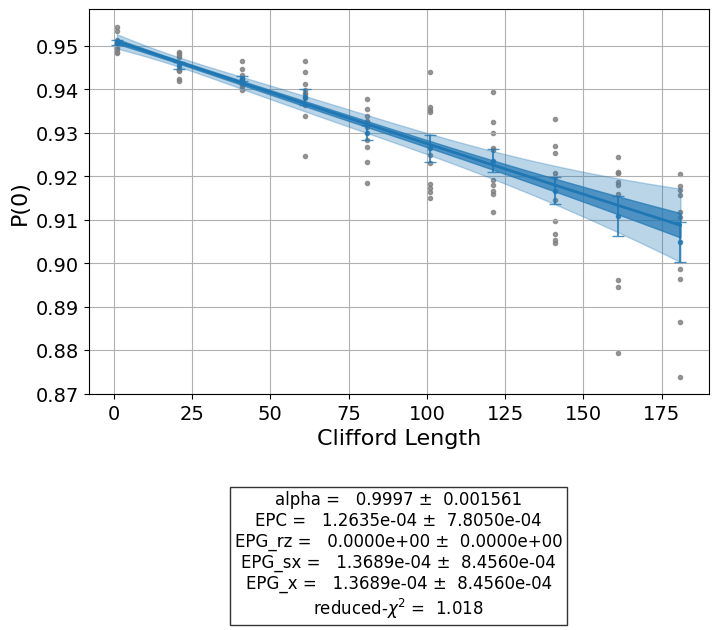

In [710]:
exp_q0_robust_reconstruct = qk_e.library.StandardRB([qubit0], lengths, num_samples=num_samples)
exp_q0_robust_data = qk_e.framework.ExperimentData(experiment=exp_q0_robust_reconstruct)
exp_q0_robust_data.add_data([provider.retrieve_job(job_id).result() for job_id in ["cr3hxnyfejy00083rvs0"]])
exp_q0_robust_reconstruct.analysis.run(exp_q0_robust_data, replace_results=True)
exp_q0_robust_result = exp_q0_robust_data.block_for_results()

print(f"Robust gateset on qubit {qubit0}")
exp_q0_robust_data.figure(0)

Robust gateset on qubit 46


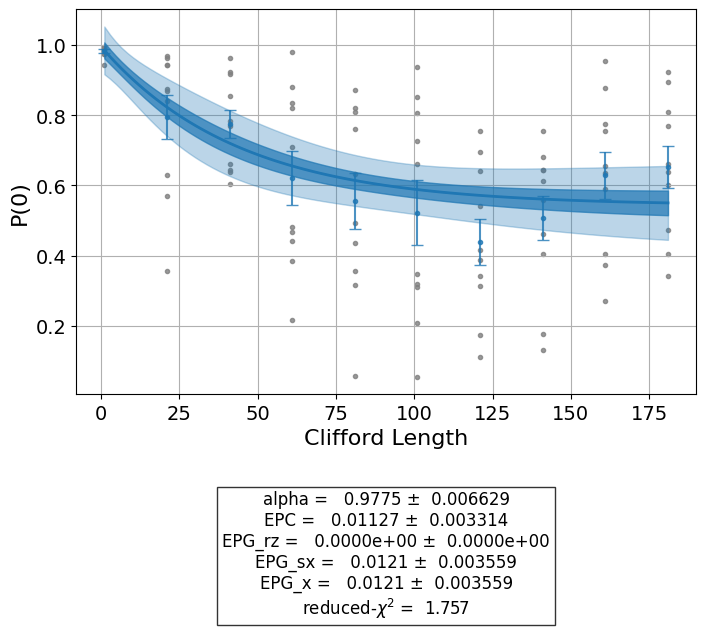

In [711]:
exp_q1_robust_reconstruct = qk_e.library.StandardRB([qubit1], lengths, num_samples=num_samples)
exp_q1_robust_data = qk_e.framework.ExperimentData(experiment=exp_q1_robust_reconstruct)
exp_q1_robust_data.add_data([provider.retrieve_job(job_id).result() for job_id in ["cr3hxpedzsgg008k9w1g"]])
exp_q1_robust_reconstruct.analysis.run(exp_q1_robust_data, replace_results=True)
exp_q1_robust_result = exp_q1_robust_data.block_for_results()

print(f"Robust gateset on qubit {qubit1}")
exp_q1_robust_data.figure(0)

Gaussian gateset on qubit 47


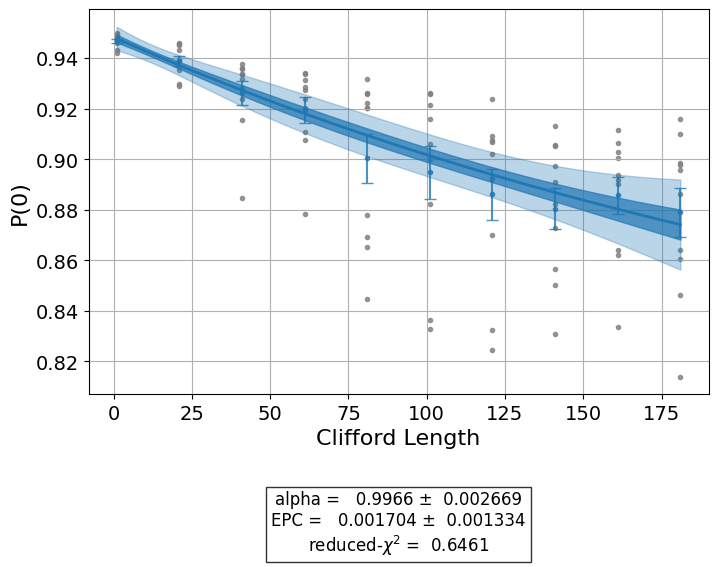

In [713]:
exp_q0_gaussian_reconstruct = qk_e.library.StandardRB([qubit1], lengths, num_samples=num_samples)
exp_q0_gaussian_data = qk_e.framework.ExperimentData(experiment=exp_q0_gaussian_reconstruct)
exp_q0_gaussian_data.add_data([provider.retrieve_job(job_id).result() for job_id in ["cr3hxq6dzsgg008k9w20"]])
exp_q0_gaussian_reconstruct.analysis.run(exp_q0_gaussian_data, replace_results=True)
exp_q0_gaussian_result = exp_q0_gaussian_data.block_for_results()

print(f"Gaussian gateset on qubit {qubit0}")
exp_q0_gaussian_data.figure(0)

Gaussian gateset on qubit 46


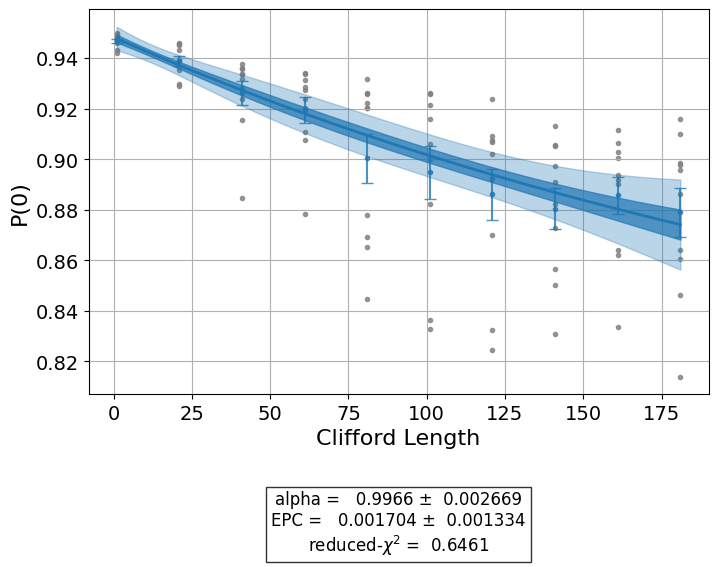

In [715]:
exp_q1_gaussian_reconstruct = qk_e.library.StandardRB([qubit1], lengths, num_samples=num_samples)
exp_q1_gaussian_data = qk_e.framework.ExperimentData(experiment=exp_q1_gaussian_reconstruct)
exp_q1_gaussian_data.add_data([provider.retrieve_job(job_id).result() for job_id in ["cr3hxq6dzsgg008k9w20"]])
exp_q1_gaussian_reconstruct.analysis.run(exp_q1_gaussian_data, replace_results=True)
exp_q1_gaussian_result = exp_q1_gaussian_data.block_for_results()

print(f"Gaussian gateset on qubit {qubit1}")
exp_q1_gaussian_data.figure(0)

In [716]:
session.cancel()
session.close()
session.status()

'Closed'